# OTT Streaming Content Trend Analysis (Netflix / Prime Video / Hulu / Disney+)
**Goal:** Go from a raw catalog dump to a narrative a content strategy team can act on.

**Dataset:** `MoviesOnStreamingPlatforms.csv` — 9,515 movies with release year, age rating, Rotten Tomatoes score and a 0/1 flag for availability on each of four platforms.

> **Scope note:** this dataset has *no genre, country or duration columns*, so the analysis focuses on what it does contain: **release-year trends, age-rating (audience) mix, critic ratings, and platform overlap/exclusivity**.

**Contents:** 1. Load & clean → 2. EDA (8 visualizations) → 3. SQL aggregations → 4. Insights & strategy memo

## 1. Load & clean

In [1]:
import pandas as pd, numpy as np, sqlite3
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi":110, "axes.titleweight":"bold", "axes.titlesize":13})
PLAT = ["Netflix","Prime Video","Hulu","Disney+"]
COL  = {"Netflix":"#E50914","Prime Video":"#00A8E1","Hulu":"#1CE783","Disney+":"#113CCF"}

df = pd.read_csv("MoviesOnStreamingPlatforms.csv")
print(df.shape); df.head()

(9515, 11)


,Unnamed: 0,ID,Title,Year,Age,Rotten Tomatoes,Netflix,Hulu,Prime Video,Disney+,Type
0,0,1,The Irishman,2019,18+,98/100,1,0,0,0,0
1,1,2,Dangal,2016,7+,97/100,1,0,0,0,0
2,2,3,David Attenborough: A Life on Our Planet,2020,7+,95/100,1,0,0,0,0
3,3,4,Lagaan: Once Upon a Time in India,2001,7+,94/100,1,0,0,0,0
4,4,5,Roma,2018,18+,94/100,1,0,0,0,0


In [2]:
print(df.isna().sum()[lambda s: s>0], "\n")
print("Duplicate titles:", df.Title.duplicated().sum())
print("Type column unique values:", df.Type.unique(), "(constant -> all rows are movies, dropped)")

Age                4177
Rotten Tomatoes       7
dtype: int64 

Duplicate titles: 0
Type column unique values: [0] (constant -> all rows are movies, dropped)


In [3]:
df = df.drop(columns=["Unnamed: 0","Type"])
df["rt"] = df["Rotten Tomatoes"].str.split("/").str[0].astype(float)   # '98/100' -> 98
df["Age"] = df["Age"].fillna("Unrated")                                  # 44% missing -> explicit category
df["decade"] = (df.Year // 10 * 10).astype(int)
df["n_platforms"] = df[PLAT].sum(axis=1)
df["acclaimed"] = df.rt >= 80
# long format: one row per (title, platform) - makes per-platform analysis easy
long = df.melt(id_vars=[c for c in df.columns if c not in PLAT], value_vars=PLAT,
               var_name="platform", value_name="on").query("on==1").drop(columns="on")
print("Cleaned:", df.shape, "| long format:", long.shape)
df[["Year","rt","n_platforms"]].describe().round(1)

Cleaned: (9515, 13) | long format: (9777, 10)


,Year,rt,n_platforms
count,9515.0,9508.0,9515.0
mean,2007.4,53.5,1.0
std,19.1,13.2,0.2
min,1914.0,10.0,1.0
25%,2006.0,44.0,1.0
50%,2015.0,52.0,1.0
75%,2018.0,62.0,1.0
max,2021.0,98.0,4.0


**Cleaning decisions:** `Type` is constant (0) so it was dropped; Rotten Tomatoes `'98/100'` strings were converted to numbers (7 missing); the 4,177 missing age ratings were kept as an explicit **Unrated** category rather than dropped, since that is 44% of the catalog. 2021 is a partial year in this data.

## 2. Exploratory analysis

### Viz 1 — Catalog size by platform

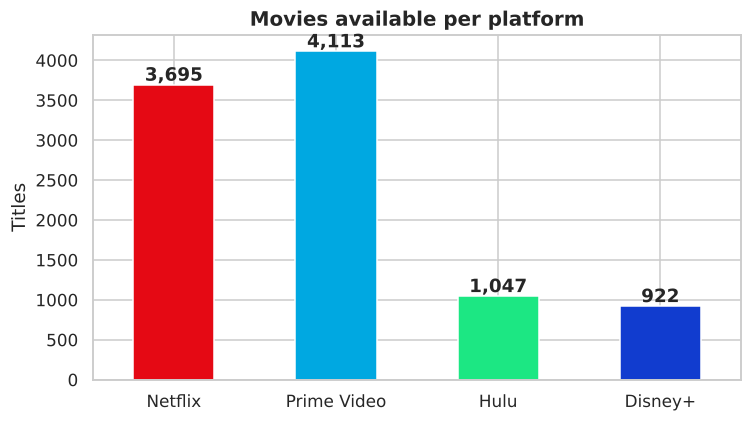

In [4]:
s = long.platform.value_counts().reindex(PLAT)
ax = s.plot.bar(color=[COL[p] for p in s.index], figsize=(7,4), rot=0)
for i,v in enumerate(s): ax.text(i, v+50, f"{v:,}", ha="center", fontweight="bold")
ax.set(title="Movies available per platform", xlabel="", ylabel="Titles"); plt.tight_layout(); plt.savefig("charts/01_catalog_size.png"); plt.show()

Prime Video (4,113) and Netflix (3,695) are close in size; Hulu and Disney+ are about a quarter the size. But size alone says little — the next charts show *what* is in each catalog.

### Viz 2 — Release-year trend: when was the catalog added/produced?

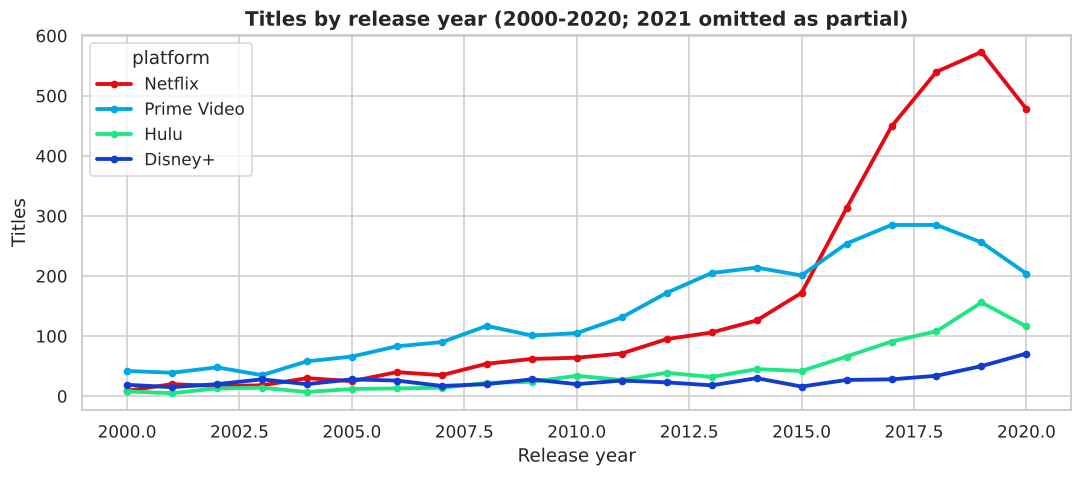

In [5]:
t = long[(long.Year>=2000)&(long.Year<=2020)].groupby(["Year","platform"]).size().unstack().reindex(columns=PLAT)
ax = t.plot(color=[COL[p] for p in PLAT], lw=2.5, figsize=(10,4.5), marker="o", ms=4)
ax.set(title="Titles by release year (2000-2020; 2021 omitted as partial)", xlabel="Release year", ylabel="Titles"); plt.tight_layout(); plt.savefig("charts/02_release_trend.png"); plt.show()

Catalog growth is almost entirely a post-2015 story, and **Netflix's 2016-2020 additions dominate** every other platform. All platforms dip in 2020, consistent with the pandemic production slowdown.

### Viz 3 — How 'new' is each library? (release-era mix)

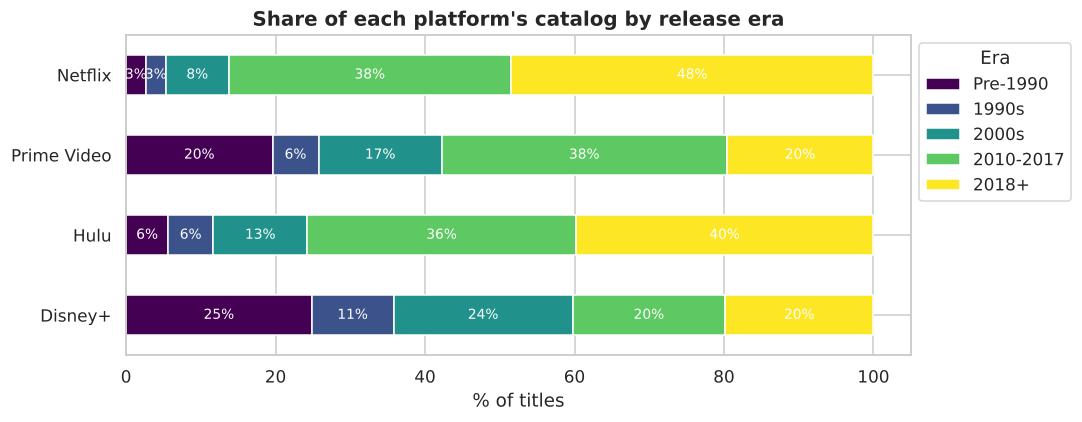

era          Pre-1990  1990s  2000s  2010-2017  2018+
platform                                             
Netflix           2.6    2.7    8.4       37.8   48.5
Prime Video      19.6    6.2   16.5       38.1   19.6
Hulu              5.6    6.0   12.6       35.9   39.8
Disney+          24.8   11.0   24.0       20.4   19.8


In [6]:
bins=[0,1989,1999,2009,2017,2030]; labels=["Pre-1990","1990s","2000s","2010-2017","2018+"]
long["era"]=pd.cut(long.Year,bins=bins,labels=labels)
e=pd.crosstab(long.platform,long.era,normalize="index").reindex(PLAT)*100
ax=e.plot.barh(stacked=True,figsize=(10,4),colormap="viridis")
for c in ax.containers: ax.bar_label(c,fmt="%.0f%%",label_type="center",color="white",fontsize=9)
ax.set(title="Share of each platform's catalog by release era",xlabel="% of titles",ylabel=""); ax.legend(title="Era",bbox_to_anchor=(1,1)); ax.invert_yaxis()
plt.tight_layout(); plt.savefig("charts/03_era_mix.png"); plt.show()
print((e.round(1)))

**Netflix is a recency play** (about 86% of titles since 2010, 48% since 2018). **Prime Video and Disney+ lean on back catalog** — ~20% and ~25% pre-1990 respectively, vs 3% for Netflix.

### Viz 4 — Audience mix: age-rating share by platform

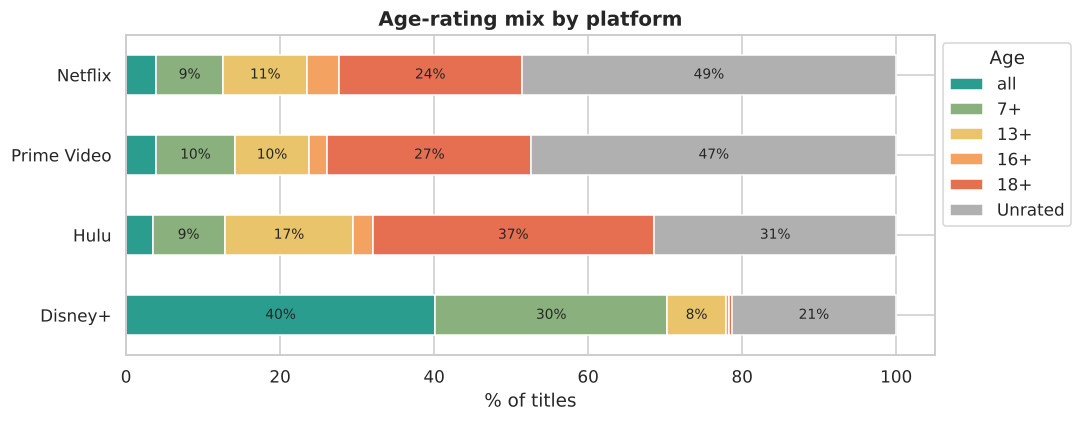

In [7]:
order=["all","7+","13+","16+","18+","Unrated"]
a=pd.crosstab(long.platform,long.Age,normalize="index")[order].reindex(PLAT)*100
ax=a.plot.barh(stacked=True,figsize=(10,4),color=["#2a9d8f","#8ab17d","#e9c46a","#f4a261","#e76f51","#b0b0b0"])
for c in ax.containers: ax.bar_label(c,fmt=lambda v:f"{v:.0f}%" if v>=5 else "",label_type="center",fontsize=9)
ax.set(title="Age-rating mix by platform",xlabel="% of titles",ylabel=""); ax.legend(title="Age",bbox_to_anchor=(1,1)); ax.invert_yaxis()
plt.tight_layout(); plt.savefig("charts/04_age_mix.png"); plt.show()

**Disney+ is the family platform** (70% rated all/7+, nearly zero 18+). **Hulu skews adult** (37% 18+ — the highest among rated catalogs). Netflix and Prime Video have only ~12-14% family-rated (all/7+) titles each, leaving the family/teen segment mostly to Disney+.

### Viz 5 — Critic ratings by platform

/tmp/ipykernel_183/615692560.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=long.dropna(subset=["rt"]),x="platform",y="rt",order=PLAT,palette=COL,ax=ax[0],showfliers=False)


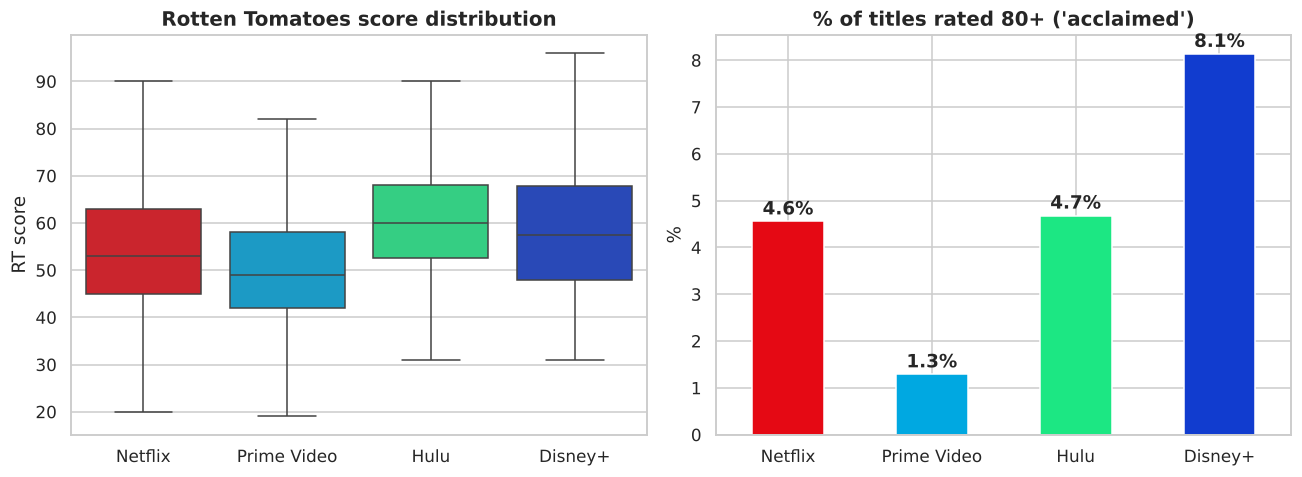

             mean  median
platform                 
Netflix      54.4    53.0
Prime Video  50.4    49.0
Hulu         60.4    60.0
Disney+      58.3    57.5


In [8]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
sns.boxplot(data=long.dropna(subset=["rt"]),x="platform",y="rt",order=PLAT,palette=COL,ax=ax[0],showfliers=False)
ax[0].set(title="Rotten Tomatoes score distribution",xlabel="",ylabel="RT score")
h=long.dropna(subset=["rt"]).groupby("platform").acclaimed.mean().reindex(PLAT)*100
h.plot.bar(color=[COL[p] for p in PLAT],ax=ax[1],rot=0)
for i,v in enumerate(h): ax[1].text(i,v+.15,f"{v:.1f}%",ha="center",fontweight="bold")
ax[1].set(title="% of titles rated 80+ ('acclaimed')",xlabel="",ylabel="%")
plt.tight_layout(); plt.savefig("charts/05_ratings.png"); plt.show()
print(long.groupby("platform").rt.agg(["mean","median"]).reindex(PLAT).round(1))

Average quality is middling everywhere (means 50-60). **Hulu has the highest typical score (60.4), Prime Video the lowest (50.4)**. Only ~3.5% of the catalog scores 80+, and Prime Video is far behind on acclaimed titles (1.3% vs 4.6-8.1%).

### Viz 6 — Does critic quality change by release decade?

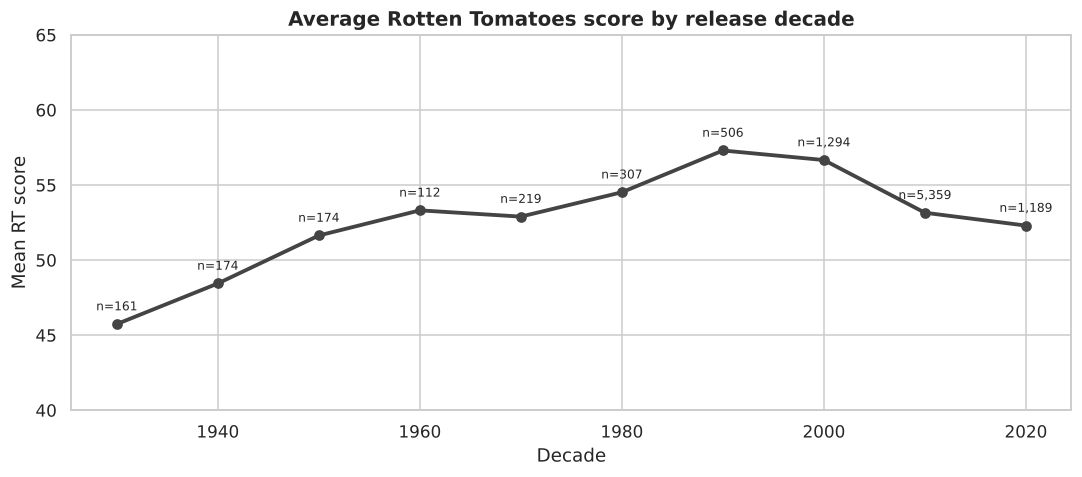

In [9]:
d=df[df.Year>=1930].groupby("decade").rt.agg(["mean","size"])
fig,ax=plt.subplots(figsize=(10,4.5)); ax.plot(d.index,d["mean"],marker="o",lw=2.5,color="#444")
for x,y,n in zip(d.index,d["mean"],d["size"]): ax.annotate(f"n={n:,}",(x,y),textcoords="offset points",xytext=(0,9),ha="center",fontsize=8)
ax.set(title="Average Rotten Tomatoes score by release decade",xlabel="Decade",ylabel="Mean RT score",ylim=(40,65)); plt.tight_layout(); plt.savefig("charts/06_rating_by_decade.png"); plt.show()

Newer is not better: the 1990s-2000s titles score highest (~57), while the 2010s (53) and 2020s (52) are lower. The 2010s account for 5,359 titles (56% of the catalog) — platforms have prioritized **volume over quality** in recent years.

### Viz 7 — Overlap & exclusivity

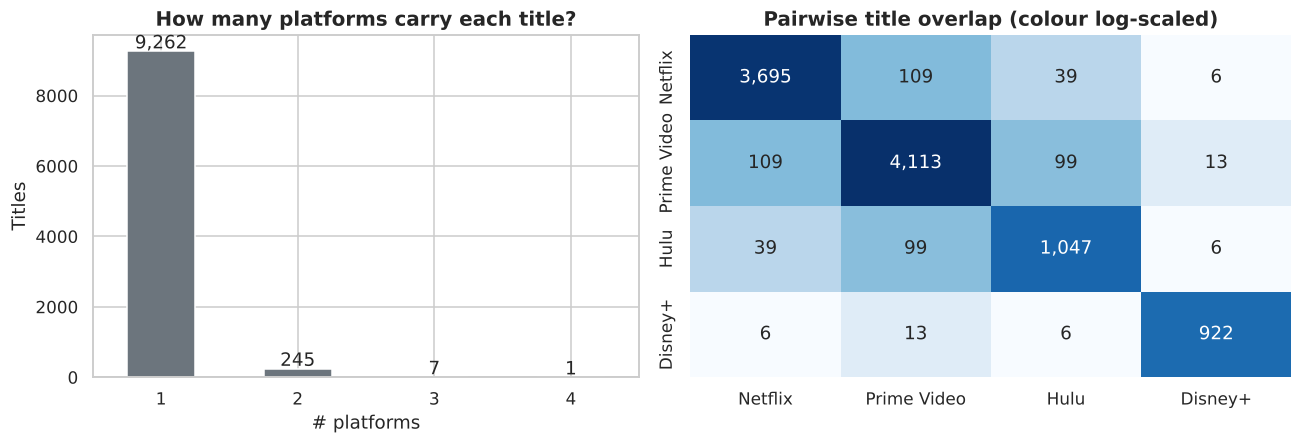

Single-platform titles: 97.3%


In [10]:
fig,ax=plt.subplots(1,2,figsize=(12,4.2),gridspec_kw={"width_ratios":[1,1.1]})
df.n_platforms.value_counts().sort_index().plot.bar(ax=ax[0],color="#6c757d",rot=0)
for i,v in enumerate(df.n_platforms.value_counts().sort_index()): ax[0].text(i,v+80,f"{v:,}",ha="center")
ax[0].set(title="How many platforms carry each title?",xlabel="# platforms",ylabel="Titles")
M=pd.DataFrame([[((df[a]==1)&(df[b]==1)).sum() for b in PLAT] for a in PLAT],index=PLAT,columns=PLAT)
sns.heatmap(M,annot=True,fmt=",",cmap="Blues",ax=ax[1],cbar=False,norm=plt.matplotlib.colors.LogNorm()); ax[1].set_title("Pairwise title overlap (colour log-scaled)")
plt.tight_layout(); plt.savefig("charts/07_overlap.png"); plt.show()
print(f"Single-platform titles: {(df.n_platforms==1).mean():.1%}")

**97.3% of titles live on exactly one platform.** The only meaningful overlap is Prime Video with Netflix (109) and Hulu (99). Each licensing/acquisition decision is effectively a zero-sum differentiator.

### Viz 8 — Where are the acclaimed titles? (platform × decade heatmap)

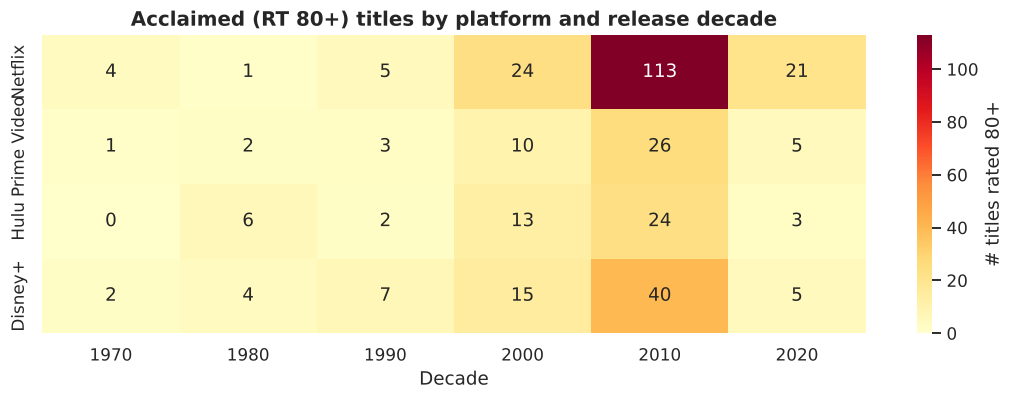

In [11]:
h=long[long.acclaimed&(long.Year>=1970)].groupby(["platform","decade"]).size().unstack(fill_value=0).reindex(PLAT)
plt.figure(figsize=(10,3.8)); sns.heatmap(h,annot=True,fmt="d",cmap="YlOrRd",cbar_kws={"label":"# titles rated 80+"})
plt.title("Acclaimed (RT 80+) titles by platform and release decade"); plt.xlabel("Decade"); plt.ylabel("")
plt.tight_layout(); plt.savefig("charts/08_acclaimed_heatmap.png"); plt.show()

Netflix's acclaimed titles are heavily concentrated in the 2010s (113 of 168), consistent with its originals push. Prime Video's acclaimed supply is thin in every decade (51 titles in total, only 26 from the 2010s). Disney+ has a steadier spread, from Mary Poppins-era classics through 2010s franchise hits (40 in the 2010s).

## 3. SQL aggregations (SQLite)
The same data is loaded into an in-memory SQLite database. The platforms are stored as columns, so each query un-pivots them with `UNION ALL` into a `platform_titles` view. All queries are also saved in `queries.sql`.

In [12]:
con = sqlite3.connect(":memory:")
raw = df.drop(columns=["Rotten Tomatoes","decade","n_platforms","acclaimed"]).rename(columns={"Prime Video":"Prime_Video","Disney+":"Disney_Plus","rt":"rt_score"})
raw.to_sql("movies", con, index=False)
con.executescript('''
CREATE VIEW platform_titles AS
  SELECT ID, Title, Year, Age, rt_score, 'Netflix'     AS platform FROM movies WHERE Netflix = 1
  UNION ALL SELECT ID, Title, Year, Age, rt_score, 'Prime Video' FROM movies WHERE Prime_Video = 1
  UNION ALL SELECT ID, Title, Year, Age, rt_score, 'Hulu'        FROM movies WHERE Hulu = 1
  UNION ALL SELECT ID, Title, Year, Age, rt_score, 'Disney+'     FROM movies WHERE Disney_Plus = 1;
''')
q = lambda sql: pd.read_sql(sql, con)

**Q1 — Catalog size, average rating and share of acclaimed titles per platform**

In [13]:
Q1 = '''
SELECT platform,
       COUNT(*)                                             AS titles,
       ROUND(AVG(rt_score), 1)                              AS avg_rt,
       ROUND(100.0 * SUM(rt_score >= 80) / COUNT(rt_score), 1) AS pct_acclaimed_80plus
FROM platform_titles
GROUP BY platform
ORDER BY titles DESC;
'''
q(Q1)

,platform,titles,avg_rt,pct_acclaimed_80plus
0,Prime Video,4113,50.4,1.3
1,Netflix,3695,54.4,4.6
2,Hulu,1047,60.4,4.7
3,Disney+,922,58.3,8.1


**Q2 — Recency: share of each catalog released 2010+ and 2018+**

In [14]:
Q2 = '''
SELECT platform,
       ROUND(100.0 * AVG(Year >= 2010), 1) AS pct_2010_plus,
       ROUND(100.0 * AVG(Year >= 2018), 1) AS pct_2018_plus,
       ROUND(100.0 * AVG(Year <  1990), 1) AS pct_pre_1990
FROM platform_titles
GROUP BY platform
ORDER BY pct_2018_plus DESC;
'''
q(Q2)

,platform,pct_2010_plus,pct_2018_plus,pct_pre_1990
0,Netflix,86.3,48.5,2.6
1,Hulu,75.7,39.8,5.6
2,Disney+,40.2,19.8,24.8
3,Prime Video,57.7,19.6,19.6


**Q3 — Age-rating mix per platform (% of catalog)**

In [15]:
Q3 = '''
SELECT platform,
       ROUND(100.0 * SUM(Age IN ('all','7+'))   / COUNT(*), 1) AS pct_family,
       ROUND(100.0 * SUM(Age IN ('13+','16+'))  / COUNT(*), 1) AS pct_teen,
       ROUND(100.0 * SUM(Age = '18+')           / COUNT(*), 1) AS pct_adult,
       ROUND(100.0 * SUM(Age = 'Unrated')       / COUNT(*), 1) AS pct_unrated
FROM platform_titles
GROUP BY platform;
'''
q(Q3)

,platform,pct_family,pct_teen,pct_adult,pct_unrated
0,Disney+,70.3,8.0,0.3,21.4
1,Hulu,12.8,19.2,36.6,31.4
2,Netflix,12.6,15.0,23.7,48.6
3,Prime Video,14.1,12.0,26.5,47.4


**Q4 — Titles added per release year by platform, with year-over-year change (window function)**

In [16]:
Q4 = '''
WITH yearly AS (
  SELECT platform, Year, COUNT(*) AS titles
  FROM platform_titles WHERE Year BETWEEN 2014 AND 2020
  GROUP BY platform, Year)
SELECT platform, Year, titles,
       titles - LAG(titles) OVER (PARTITION BY platform ORDER BY Year) AS yoy_change
FROM yearly
ORDER BY platform, Year;
'''
q(Q4).pivot(index="Year",columns="platform",values="yoy_change")

platform,Disney+,Hulu,Netflix,Prime Video
Year,,,,
2014,NaN,NaN,NaN,NaN
2015,-14.0,-3.0,46.0,-13.0
2016,11.0,24.0,141.0,53.0
2017,1.0,25.0,136.0,31.0
2018,6.0,17.0,91.0,0.0
2019,16.0,48.0,33.0,-29.0
2020,21.0,-40.0,-95.0,-52.0


**Q5 — Top 5 highest-rated titles on each platform (RANK window function)**

In [17]:
Q5 = '''
SELECT platform, Title, Year, rt_score FROM (
  SELECT *, ROW_NUMBER() OVER (PARTITION BY platform ORDER BY rt_score DESC, Year DESC) AS rn
  FROM platform_titles WHERE rt_score IS NOT NULL)
WHERE rn <= 5
ORDER BY platform, rt_score DESC;
'''
q(Q5)

,platform,Title,Year,rt_score
0,Disney+,Mary Poppins,1964,96.0
1,Disney+,Avengers: Endgame,2019,90.0
2,Disney+,Avengers: Infinity War,2018,90.0
3,Disney+,Soul,2020,89.0
4,Disney+,Guardians of the Galaxy,2014,89.0
5,Hulu,The Dark Knight,2008,94.0
6,Hulu,Minding the Gap,2018,90.0
7,Hulu,Parasite,2019,88.0
8,Hulu,Batman Begins,2005,88.0
9,Hulu,Gone Girl,2014,87.0


**Q6 — Exclusivity: how many titles appear on only one platform, and which platform pairs share titles**

In [18]:
Q6 = '''
SELECT CASE WHEN n = 1 THEN 'single platform' ELSE n || ' platforms' END AS availability,
       COUNT(*) AS titles,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM movies), 1) AS pct
FROM (SELECT Netflix + Prime_Video + Hulu + Disney_Plus AS n FROM movies)
GROUP BY n ORDER BY n;
'''
display(q(Q6))
Q6b = '''
SELECT SUM(Netflix AND Prime_Video) AS netflix_prime, SUM(Netflix AND Hulu) AS netflix_hulu,
       SUM(Prime_Video AND Hulu) AS prime_hulu,       SUM(Disney_Plus AND Prime_Video) AS disney_prime
FROM movies;
'''
q(Q6b)

,availability,titles,pct
0,single platform,9262,97.3
1,2 platforms,245,2.6
2,3 platforms,7,0.1
3,4 platforms,1,0.0


,netflix_prime,netflix_hulu,prime_hulu,disney_prime
0,109,39,99,13


**Q7 — Average rating by decade and platform (decades with at least 30 titles)**

In [19]:
Q7 = '''
SELECT (Year/10)*10 AS decade, platform, COUNT(*) AS titles, ROUND(AVG(rt_score),1) AS avg_rt
FROM platform_titles
WHERE Year >= 1980
GROUP BY decade, platform
HAVING COUNT(*) >= 30
ORDER BY decade, platform;
'''
q(Q7).pivot(index="decade",columns="platform",values="avg_rt")

platform,Disney+,Hulu,Netflix,Prime Video
decade,,,,
1980,62.0,67.6,50.9,52.3
1990,63.1,63.8,58.4,52.9
2000,61.3,66.6,60.2,52.3
2010,60.0,59.0,54.1,49.9
2020,49.1,57.7,52.8,49.0


## 4. Insights

| # | Finding | Evidence |
|---|---|---|
| 1 | **Libraries have different identities.** Netflix is a "fresh content" library; Prime Video and Disney+ rely on back catalog. | 86% of Netflix titles are 2010+ (48% since 2018) vs 58% / 40% for Prime / Disney+. ~20-25% of Prime and Disney+ are pre-1990. |
| 2 | **Volume ≠ quality.** Prime Video has the biggest catalog but the weakest ratings and almost no acclaimed titles. | Prime: avg RT 50.4, 1.3% rated 80+. Hulu avg 60.4; Disney+ 8.1% acclaimed. Only 3.5% of all titles are 80+. |
| 3 | **Audience whitespace.** Disney+ owns family; Hulu owns adult; Netflix/Prime are adult-skewed with little teen/family depth. | Disney+ 70% all/7+; Netflix 13%, Prime 14% all/7+. Hulu 37% 18+. |
| 4 | **Almost no overlap.** 97% of titles exist on one platform only. | 9,262 of 9,515 titles single-platform. |
| 5 | **Data-quality caveat.** 44% of titles lack an age rating and score lower on average (47 vs 55-61). | Age missing ⇒ likely niche/older/low-profile titles. |

## 5. Content Strategy Memo
See **`content_strategy_memo.md`** for the stakeholder-ready version (3 actionable insights, written for a content acquisition team).

**Limitations:** no genre/country/duration fields were available, so no genre-mix or regional analysis was possible; ratings are Rotten Tomatoes only; the dataset is a point-in-time snapshot (2021 is partial); and the platform flags indicate availability, not originals vs licensed.